Sample rate: 48000, Duration: 56.50 seconds


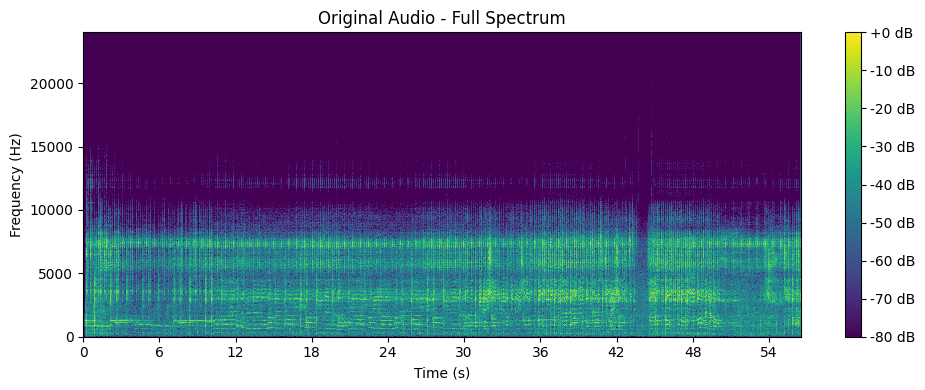

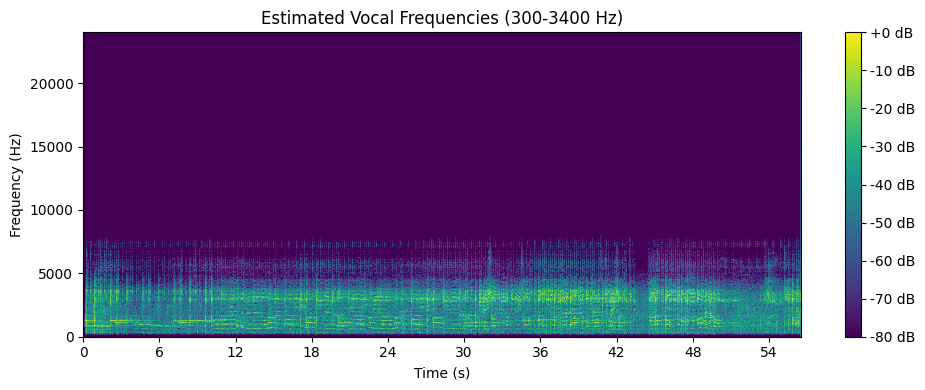

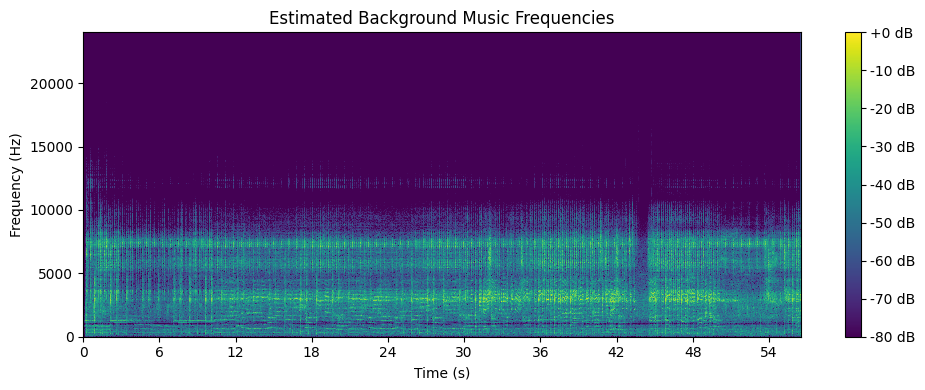

In [2]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import butter, lfilter
# --- 1. Load Audio File ---
filename = 'HN.mp3'
y, sr = librosa.load(filename, sr=None)
print(f"Sample rate: {sr}, Duration: {len(y)/sr:.2f} seconds")
# --- 2. Bandpass Filter for Vocals (Speech: 300–3400 Hz) ---
def butter_bandpass(lowcut, highcut, fs, order=6):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a
def bandpass_filter(data, lowcut, highcut, fs, order=6):
    b, a = butter_bandpass(lowcut, highcut, fs, order)
    return lfilter(b, a, data)
vocal_band = bandpass_filter(y, lowcut=300, highcut=3400, fs=sr)
background_band = y - vocal_band
# Approximation: remaining frequencies as background
# --- 3. Display Spectrograms (STFT) ---
def plot_spectrogram(signal, sr, title):
    D = librosa.amplitude_to_db(np.abs(librosa.stft(signal)),
ref=np.max)
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='hz',
cmap='viridis')
    plt.colorbar(format='%+2.0f dB')
    plt.title(title)
    plt.xlabel('Time (s)')
    plt.ylabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()
plot_spectrogram(y, sr, 'Original Audio - Full Spectrum')
plot_spectrogram(vocal_band, sr, 'Estimated Vocal Frequencies (300-3400 Hz)')
plot_spectrogram(background_band, sr, 'Estimated Background Music Frequencies')

# --- 4. Optional: Save Filtered Audio ---
sf.write('filtered_vocals.wav', vocal_band, sr)
sf.write('estimated_background.wav', background_band, sr)